# 03 · Verification: correctness and numerical stability

Every claim the method rests on, checked numerically on the solver core (`parampc.core`). Each test compares with a
reference that shares no code with the scan (dense linear algebra in NumPy, `parampc.testing`) or with an exact
mathematical statement.

| test | claim |
|---|---|
| **T1** | the value-function combine is associative |
| **T2** | the scan solves the Newton system to round-off, like dense LU on the full matrix |
| **T3** | without inequalities, one Newton step solves the MPC problem |
| **T4** | the IPM reaches a certified optimum with active constraints; scan = sweep |
| **T5** | past the attainable accuracy the raw IPM degrades; `core.ipm` stops and returns its best iterate |
| **T6** | a semidefinite cost (output-only or terminal-only) is solved: the scan falls back to the LU combine; scan = sweep = dense certificate |
| **T7** | the IPM options (Gondzio correctors, Mehrotra's start, unrefined predictor, `combine='chol'`) reach the same certified optimum |
| **T8** | `core.cholesky_ok` accepts definite costs and rejects semidefinite ones |
| **T9** | the whole IPM as one CUDA kernel (`method='cuda'`) gives the JAX IPM's iterates and certified optima, including the LU fallback and the closed loop; with `precision='float32'` (a single-precision factorization while $\mu>10^{-5}$) the same certified optima as the JAX IPM with that switch; skipped without a GPU |
| **S1** | the scan's elements are Riccati/filter recursions; the segment closed-loop identity |
| **S2** | the combine is non-expansive in the Thompson metric |
| **S3** | $\bar Q\succeq\beta I$ makes the closed loop contract; every scan element is bounded |
| **S4** | the first-order error identity of the scan |
| **S5** | float32 error does not grow with $N$ (beyond the tree height), scan vs sweep |
| **S6** | extreme barrier weights: the scan's accuracy matches the sweep's, on inputs and on the quadrotor QP ($\kappa\approx10^{15}$) |
| **S7** | without detectability the LQ problem is exponentially ill-conditioned: scan and sweep both lose accuracy; $\lambda>0$ repairs both |
| **S8** | the quasi (diagonal) variant fails when a state channel has no direct actuation |
| **S9** | shooting on the costate: eigenvalues pair with the closed loop; $\kappa(\Phi^N)\ge\mu_{\min}^{-2N}$ |
| **S10** | a float32 factorization with float64 refinement cannot reach the quadrotor tolerance (negative result); in the early iterations only (`precision='float32'`) it costs neither accuracy nor iterations |

Section 3 runs the tests; Section 4 prints every result, the pass/fail summary and the plots. The notebook runs on
the CPU (float32 comparisons are meaningless on a GPU that uses TF32 matmuls); T9 runs in a GPU subprocess.

## 0. Import Dependencies

In [1]:
import json
import os
import subprocess
import sys

os.environ['JAX_PLATFORMS'] = 'cpu'                 # T9 starts its own GPU process
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as sla
from jax import lax
from jax.flatten_util import ravel_pytree

import parampc as pm
from parampc import core, testing
from parampc.models import quadrotor as quad
from parampc.solver import to_core

%config InlineBackend.figure_formats = ['svg']    # figures as vector graphics

print(f"parampc {pm.__version__} | jax {jax.__version__} | backend {jax.default_backend()} | "
      f"float64 {jax.config.jax_enable_x64}")

parampc 0.1.0 | jax 0.11.1 | backend cpu | float64 True


## 1. Parameter Declaration

Problem sizes, seeds and pass thresholds of every test. The thresholds are round-off level for float64 tests and a
few hundred float32 units for the float32 tests.

In [2]:
U32 = float(np.finfo(np.float32).eps) / 2          # float32 unit roundoff

T2_SIZES = [(16, 3, 2, 6), (32, 4, 2, 8), (64, 8, 4, 10)]            # (N, n, m, M)
T4_CASES = [(64, 4, 2, 8, 0.05, 0.5), (128, 6, 3, 12, 0.05, 0.3)]    # (N, n, m, M, u_max, x_max)
T4_TOL = 1e-10                                     # IPM tolerance used for the certificate
T6_CASES = [(32, 4, 2), (128, 6, 2)]               # (N, n, m), semidefinite cost
S5_HORIZONS = [16, 64, 256, 1024, 4096]
S7_HORIZONS = [32, 64, 128, 256, 1024]
S7_LAMBDA = 1e-3                                   # BVP-ELK regularization
S8_HORIZONS = [30, 100, 300]

TOL = dict(T1=1e-12, T2=1e-10, T3=1e-12, T4=1e-8, S1=1e-12, S2=1 + 1e-6, S4=1e-6, S6=1e-12)

## 2. Aux Functions

- **Scan internals.** `scan_elements` builds the value-function elements; `scan_P` and `sweep_P` are the cost-to-go
  matrices $P_t$ exactly as the solver computes them: the scan path of `core.factor_lq` (with its LU fallback for a
  semidefinite cost) and the Riccati recursion `core.riccati_sweep`. `gains` gives the feedback $K_t$ and
  `transition` the closed-loop transition $\Psi_{i\to j} = (A_{j-1}-B_{j-1}K_{j-1})\cdots(A_i-B_iK_i)$. `fold`
  composes the elements of a segment $[i,j)$ sequentially.
- **Test problems.** `semidefinite_problem` makes the cost of a random problem semidefinite (T6). `quad_qp` is the
  quadrotor's SQP subproblem (by default at the hover initial guess) in the core's data layout.
- **Metrics.** `thompson` is the Thompson (part) metric $d(X,Y)=\max_i|\log\lambda_i(X^{-1}Y)|$, the natural relative
  error of a positive definite matrix. `rel_err` is the normwise relative error.
- **Quasi variant.** The diagonal combine and the diagonal scan. They are not part of the package; they exist only
  to test the negative result.
- **Shooting.** `shooting_matrix` is the one-stage transition of the costate recursion, and `lqr_closed_loop` the
  infinite-horizon LQR closed loop.

In [3]:
def flip(tree):
    return jax.tree.map(lambda e: jnp.flip(e, 0), tree)


def scan_elements(lq, data):
    """Stage elements (Abar, M, Qbar) plus the terminal element (0, 0, Qt_N)."""
    n, dt = data['A'].shape[-1], data['A'].dtype
    zero = jnp.zeros((1, n, n), dt)
    return tuple(jnp.concatenate([e, last]) for e, last in
                 zip(core.stage_elements(lq, data), (zero, zero, lq['QtN'][None])))


scan_P = jax.jit(lambda lq, data: core.factor_lq(lq, data, 'scan')['P'])
sweep_P = jax.jit(core.riccati_sweep)


def semidefinite_problem(N, n, m, seed, terminal_only=False):
    """random_problem with input boxes only and a semidefinite cost: only the output y = x_1 is penalized
    (Q = QN = c c'), or only the terminal state (Q = 0, QN = I)."""
    data, z0 = testing.random_problem(N, n, m, 2 * m, seed=seed)
    if terminal_only:
        return dict(data, Q=0 * data['Q'], QN=jnp.eye(n)), z0
    cc = jnp.outer(jnp.eye(n)[0], jnp.eye(n)[0])
    return dict(data, Q=jnp.broadcast_to(cc, data['Q'].shape), QN=cc), z0


def quad_qp(N, state=None, ctrl=None, floor=1.0):
    """The quadrotor's SQP subproblem at `state` (default: the hover initial guess) in the core's data layout, with
    the starting point at the linearization point (multipliers of `state`, floored at `floor`; default: cold)."""
    ctrl = ctrl or pm.NMPC(quad.ocp(N), **quad.NMPC_OPTIONS)
    x0, SR = quad.initial_state(), quad.horizon_reference(0.0, N)
    state = state or ctrl.init(x0, SR)
    data = to_core(ctrl.qp(state.X, state.U, SR, x0))
    lam = state.lam if floor < 1.0 else 1.0
    return data, core.initial_iterate(data, state.X, state.U, lam, floor)


def gains(lq, data, P):
    BtP = data['B'].mT @ P[1:]
    return jnp.linalg.solve(lq['Rt'] + BtP @ data['B'], BtP @ data['A'] + lq['St'])


def transition(Acl, i, j):
    Psi = np.eye(Acl.shape[-1])
    for k in range(i, j):
        Psi = np.asarray(Acl[k]) @ Psi
    return Psi


def fold(elems, i, j):
    e = tuple(x[i] for x in elems)
    for k in range(i + 1, j):
        e = core.vf_combine(e, tuple(x[k] for x in elems))
    return tuple(np.asarray(x) for x in e)


def thompson(X, Y):
    X, Y = np.asarray(X, np.float64), np.asarray(Y, np.float64)
    if X.ndim == 2:
        X, Y = X[None], Y[None]
    d = 0.0
    for a, b in zip(X, Y):
        ev = sla.eigh(0.5 * (a + a.T), 0.5 * (b + b.T), eigvals_only=True)
        d = max(d, np.abs(np.log(ev)).max()) if ev.min() > 0 else np.inf
    return d


def rel_err(Xhat, X):
    Xhat, X = np.asarray(Xhat, np.float64), np.asarray(X, np.float64)
    if not np.isfinite(Xhat).all():
        return np.inf
    return np.max(np.linalg.norm(Xhat - X, ord=2, axis=(-2, -1)) / np.linalg.norm(X, ord=2, axis=(-2, -1)))


def cast(tree, dtype):
    return jax.tree.map(lambda a: jnp.asarray(a, dtype), tree)


def lq_of(data, z, tau=1.0):
    """The condensed LQ problem at z: barrier-augmented matrices and right-hand side."""
    return dict(core.barrier_hessians(data, z), **core.lq_rhs(data, z, core.residuals(data, z, tau)))


def linearized_residual(data, z, method, tau):
    """|F(z) + J(z) dz| / |F(z)| for the Newton step dz computed by `method`."""
    step = core.newton_step(data, z, tau, method=method)
    F = lambda zz: ravel_pytree(core.residuals(data, zz, tau))[0]
    F0, JdZ = jax.jvp(F, (z,), (step,))
    return float(jnp.max(jnp.abs(F0 + JdZ)) / jnp.max(jnp.abs(F0)))


# ---- the quasi (diagonal) variant
def diag_combine(a1, a2):
    A1, C1, J1 = a1
    A2, C2, J2 = a2
    X = 1.0 / (1.0 + C1 * J2)
    return A2 * X * A1, A2 * X * C1 * A2 + C2, A1 * X * J2 * A1 + J1


def diag_scan_P(lq, data):
    d = lambda M: jnp.diagonal(M, axis1=-2, axis2=-1)
    return flip(lax.associative_scan(lambda a1, a2: diag_combine(a2, a1),
                                     flip(tuple(d(e) for e in scan_elements(lq, data)))))[2]


# ---- shooting on the costate
def shooting_matrix(A, B, Q, R, S):
    Abar = A - B @ np.linalg.solve(R, S)
    M = B @ np.linalg.solve(R, B.T)
    Qbar = Q - S.T @ np.linalg.solve(R, S)
    Ai = np.linalg.inv(Abar.T)
    return np.block([[Abar + M @ Ai @ Qbar, -M @ Ai], [-Ai @ Qbar, Ai]])


def lqr_closed_loop(A, B, Q, R, S):
    P = sla.solve_discrete_are(A, B, Q, R, s=S.T)
    return A - B @ np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A + S)


newton_jit = jax.jit(core.newton_step, static_argnames=('method',))
ipm_iteration = jax.jit(core.ipm_iteration)
certificate = lambda c: max(v for k, v in c.items() if k != 'objective')
results = {}                                       # test -> (measured, threshold, passed)

## 3. Tests

### Correctness

**T1.** Compose random elements $(A, C, J)$ with $C\succeq0$, $J\succ0$ in both bracketings.

**T2.** Build the full Newton matrix $\nabla F_\tau(z)$ with `jax.jacfwd` and solve it with dense LU. Compare
**relative KKT residuals** $\|\nabla F_\tau\Delta z + F_\tau\|_\infty/\|F_\tau\|_\infty$, not solutions: on an
ill-conditioned Newton matrix, two equally good solvers can return solutions that differ far more than their
residuals do. The test uses the starting point and an iterate six IPM steps in, where $\lambda/s$ spans many
decades. Condensing $(\Delta\lambda, \Delta s)$ away costs accuracy there, because the recovery
$\Delta\lambda = W v + w$ multiplies errors by the barrier weights; one step of iterative refinement with the same
factorization recovers it. The claim tested: scan and sweep both reach round-off level, as dense LU does on the
full matrix.

**T3.** With no inequalities every row of $F$ is affine, so Newton's method is exact in one step from any starting
point. The reference is a direct dense KKT solve in NumPy.

**T4.** Tight bounds make many constraints active. At the IPM's point $(w, \nu, \lambda)$, the KKT certificate of
the dense QP (stationarity, feasibility, $\lambda\ge0$, complementarity) must vanish.

**T5.** Run the raw IPM iteration, without any stopping rule, on a quadrotor SQP subproblem. After it reaches its
attainable accuracy, $\mu$ keeps shrinking, $\lambda/s$ explodes, and later iterates get worse, eventually NaN.
`core.ipm` stops at `tol`, $\mu<\mu_{\min}$ or `max_iter`, and returns the most accurate iterate it has seen.

**T6.** A semidefinite cost with input constraints only: only the output $y=x_1$ is penalized ($Q=Q_N=cc^\top$, the
usual output-tracking setup), or only the terminal state ($Q=0$). Then $\bar Q_t$ is singular, the Cholesky combine
breaks down (checked), and `core.factor_lq` redoes the scan with the LU combine. The random plants are stable, so
the problem stays well-posed. The IPM with the scan must reach the optimum certified by the dense QP, with the same
objective as the sweep.

**T7.** The T4 problems, solved with each IPM option: the predictor refined and no centrality corrector, the default
(unrefined predictor, one Gondzio corrector), Mehrotra's starting point, two correctors, and `combine='chol'`. Every
result must pass the dense KKT certificate of T4, with the same objective.

**T8.** `core.cholesky_ok` checks $\bar Q_t\succ0$ and $Q_N\succ0$ on the data. It must accept the T4 problems and the
quadrotor QP (whose Levenberg–Marquardt term makes the cost definite) and reject both semidefinite costs of T6.

**T9.** In a subprocess on the GPU (if there is one): the CUDA solver (`method='cuda'`, one kernel launch per QP)
against the JAX IPM, on random problems with $n=4,5,8,12$ (each size compiles its own kernel), both semidefinite
costs of T6 (the kernel's LU fallback), cold and warm-started quadrotor QPs: same iteration count, inputs equal to
round-off, and the dense KKT certificate of T4. Its attainable accuracy on the quadrotor QP (run with tolerance 0)
must stay below $10^{-8}$, and the 20 s closed loop must track identically.

In [4]:
# ---- T1: associativity
rng = np.random.default_rng(0)


def random_element(k=5):
    L1, L2 = rng.normal(size=(2, k, k))
    return rng.normal(size=(k, k)), L1 @ L1.T / k, L2 @ L2.T / k + 0.1 * np.eye(k)     # (A, C, J), J > 0


t1 = 0.0
for _ in range(16):
    a, b, c = random_element(), random_element(), random_element()
    left = core.vf_combine(core.vf_combine(a, b), c)
    right = core.vf_combine(a, core.vf_combine(b, c))
    t1 = max(t1, max(float(jnp.max(jnp.abs(x - y))) for x, y in zip(left, right)))
results['T1 associativity'] = (t1, TOL['T1'], t1 < TOL['T1'])

# ---- T2: Newton step vs dense LU
t2_rows = []
for (N, n, m, M) in T2_SIZES:
    data, z = testing.random_problem(N, n, m, M, seed=N, u_max=0.05, x_max=0.5)
    for k in range(7):
        if k in (0, 6):
            tau = 0.1 * float(jnp.mean(z['lam'] * z['s']))
            J, F, _ = testing.newton_matrix(data, z, tau)
            res = lambda v: np.max(np.abs(J @ v + F)) / np.max(np.abs(F))
            r = {md_: res(np.asarray(ravel_pytree(newton_jit(data, z, tau, method=md_))[0]))
                 for md_ in ('scan', 'sweep')}
            t2_rows.append((N, n, m, M, k, np.linalg.cond(J), res(np.linalg.solve(J, -F)), r['scan'], r['sweep']))
        z = ipm_iteration(data, z)
t2 = max(max(row[7], row[8]) for row in t2_rows)
results['T2 Newton step residual'] = (t2, TOL['T2'], t2 < TOL['T2'])

# ---- T3: equality-constrained problem, one step
data, z0 = testing.random_problem(40, 4, 2, 0, seed=2)
z0 = dict(z0, x=z0['x'] + 1.0, u=z0['u'] - 0.5)                        # arbitrary, infeasible start
z1 = jax.tree.map(jnp.add, z0, newton_jit(data, z0, 0.0))
worst = lambda z: max(float(jnp.max(jnp.abs(v))) for v in core.residuals(data, z, 0.0).values() if v.size)
w_ref, _ = testing.solve_equality_qp(testing.dense_qp(data))
t3 = (worst(z0), worst(z1), float(np.max(np.abs(testing.pack(z1)[0] - w_ref))))
results['T3 one-step exactness'] = (max(t3[1], t3[2]), TOL['T3'], max(t3[1], t3[2]) < TOL['T3'])

# ---- T4: certified optimum with active constraints
t4_rows = []
for (N, n, m, M, u_max, x_max) in T4_CASES:
    data, z0 = testing.random_problem(N, n, m, M, seed=3, u_max=u_max, x_max=x_max)
    dense = testing.dense_qp(data)
    for method in ('scan', 'sweep'):
        z, iters, _ = core.ipm(data, z0, tol=T4_TOL, method=method)
        w = testing.pack(z)[0]
        cert = testing.kkt_certificate(dense, z)
        active = int(np.sum(dense['h'] - dense['G'] @ w < 1e-7))
        t4_rows.append((N, n, m, M, method, int(iters), active, dense['h'].size, cert))
t4 = max(certificate(row[8]) for row in t4_rows)
t4_obj = max(abs(t4_rows[i][8]['objective'] - t4_rows[i + 1][8]['objective']) for i in (0, 2))
results['T4 certified optimum'] = (t4, TOL['T4'], t4 < TOL['T4'] and t4_obj < 1e-10)

# ---- T5: the raw IPM iteration past convergence, on a quadrotor SQP subproblem
Nq = 30
xq0, SRq = quad.initial_state(), quad.horizon_reference(0.0, Nq)
sqp = pm.NMPC(quad.ocp(Nq), backend='scan', **dict(quad.NMPC_OPTIONS, sqp_iters=1))
state = sqp.init(xq0, SRq)
for _ in range(14):                                                    # the 15th SQP subproblem
    state, _ = sqp.solve(state, xq0, SRq)
qp15, z15 = quad_qp(Nq, state, sqp)
z = z15
t5_trace = []
for _ in range(30):
    z = ipm_iteration(qp15, z)
    t5_trace.append((float(core.kkt_score(qp15, z)), float(jnp.mean(z['lam'] * z['s']))))
t5_trace = np.array(t5_trace)
z_stop, it_stop, _ = core.ipm(qp15, z15, tol=1e-6)
t5_stop_score = float(core.kkt_score(qp15, z_stop))
t5_raw_nan = int(np.flatnonzero(~np.isfinite(t5_trace[:, 0]))[0]) + 1 if not np.isfinite(t5_trace[:, 0]).all() else None
t5_best_raw = float(np.nanmin(t5_trace[:int(it_stop), 0]))
t5_ok = t5_stop_score < 1e-6 and abs(t5_stop_score - t5_best_raw) <= 1e-12 * t5_best_raw
results['T5 stopping rule, best iterate'] = (t5_stop_score, 1e-6, t5_ok)

# ---- T6: semidefinite cost (the Cholesky combine breaks down; LU fallback)
t6_rows = []
for terminal_only in (False, True):
    for (N, n, m) in T6_CASES:
        data, z0 = semidefinite_problem(N, n, m, seed=N, terminal_only=terminal_only)
        chol_breaks = not bool(jnp.all(jnp.isfinite(core.riccati_scan(core.barrier_hessians(data, z0), data))))
        dense = testing.dense_qp(data)
        runs = []
        for method in ('scan', 'sweep'):
            z, iters, _ = core.ipm(data, z0, tol=T4_TOL, method=method)
            runs.append((int(iters), testing.kkt_certificate(dense, z)))
        t6_rows.append(('Q = 0, QN = I' if terminal_only else "Q = QN = c c'", N, n, m, chol_breaks, runs))
t6 = max(certificate(c) for row in t6_rows for _, c in row[5])
t6_obj = max(abs(row[5][0][1]['objective'] - row[5][1][1]['objective']) for row in t6_rows)
results['T6 semidefinite cost'] = (t6, TOL['T4'], t6 < TOL['T4'] and t6_obj < 1e-10 and all(r[4] for r in t6_rows))

# ---- T7: IPM options reach the same certified optimum
T7_OPTIONS = {'predictor refined, no corrector': dict(refine_pred=1, n_corr=0), 'default': dict(),
              "Mehrotra's start": dict(start='mehrotra'), 'two Gondzio correctors': dict(n_corr=2),
              "combine='chol'": dict(combine='chol')}
t7_rows = []
for (N, n, m, M, u_max, x_max) in T4_CASES:
    data, z0 = testing.random_problem(N, n, m, M, seed=3, u_max=u_max, x_max=x_max)
    dense = testing.dense_qp(data)
    for name, opts in T7_OPTIONS.items():
        z, iters, _ = core.ipm(data, z0, tol=T4_TOL, **opts)
        t7_rows.append((N, name, int(iters), testing.kkt_certificate(dense, z)))
t7 = max(certificate(c) for *_, c in t7_rows)
t7_gap = {N: N * M * T4_TOL for (N, n, m, M, _, _) in T4_CASES}          # duality gap the tolerance allows
t7_spread = {N: max(c['objective'] for N_, _, _, c in t7_rows if N_ == N)
             - min(c['objective'] for N_, _, _, c in t7_rows if N_ == N) for N in t7_gap}
results['T7 IPM options, same optimum'] = (t7, TOL['T4'],
                                           t7 < TOL['T4'] and all(t7_spread[N] < t7_gap[N] for N in t7_gap))

# ---- T8: cholesky_ok separates definite from semidefinite costs
t8_rows = []
for (N, n, m, M, u_max, x_max) in T4_CASES:
    data, _ = testing.random_problem(N, n, m, M, seed=3, u_max=u_max, x_max=x_max)
    t8_rows.append((f'random problem N = {N}', True, bool(core.cholesky_ok(data))))
t8_rows.append(('quadrotor QP (lm = 0.5)', True, bool(core.cholesky_ok(quad_qp(30)[0]))))
for terminal_only in (False, True):
    data, _ = semidefinite_problem(32, 4, 2, seed=32, terminal_only=terminal_only)
    t8_rows.append(('Q = 0, QN = I' if terminal_only else "Q = QN = c c'", False, bool(core.cholesky_ok(data))))
t8_wrong = sum(expected != got for _, expected, got in t8_rows)
results['T8 Cholesky validity check'] = (float(t8_wrong), 0.5, t8_wrong == 0)

# ---- T9: the whole IPM as one CUDA kernel (method='cuda') = the JAX IPM, in a GPU subprocess
T9_SCRIPT = """
import json, jax, jax.numpy as jnp
import parampc as pm
from parampc import core, testing
from parampc.models import quadrotor as quad
from parampc.solver import to_core
def cert(data, z):
    c = testing.kkt_certificate(data, z)
    return max(v for k, v in c.items() if k != 'objective')
def run(data, z0, tol, mu_min=1e-12, precision='float64'):
    (zj, kj, _), (zc, kc, _) = (core.ipm(data, z0, tol=tol, mu_min=mu_min, method=md, precision=precision)
                                for md in ('scan', 'cuda'))
    return zj, zc, dict(its=[int(kj), int(kc)], kkt=[float(core.kkt_score(data, zj)), float(core.kkt_score(data, zc))],
                        du=float(jnp.max(jnp.abs(zj['u'] - zc['u'])) / jnp.max(jnp.abs(zj['u']))))
def quad_qp(N, state=None, ctrl=None, floor=1.0):
    ctrl = ctrl or pm.NMPC(quad.ocp(N), **quad.NMPC_OPTIONS)
    x0, SR = quad.initial_state(), quad.horizon_reference(0.0, N)
    state = state or ctrl.init(x0, SR)
    data = to_core(ctrl.qp(state.X, state.U, SR, x0))
    return data, core.initial_iterate(data, state.X, state.U, state.lam if floor < 1.0 else 1.0, floor)
cases, floor, cases32 = [], [], []
for (N, n, m, M, umax, xmax) in [(40, 4, 2, 8, 0.05, 0.5), (37, 5, 2, 10, 0.05, 0.5), (64, 8, 4, 10, 0.05, 0.5),
                                 (50, 12, 3, 30, 0.8, 50.0)]:
    data, z0 = testing.random_problem(N, n, m, M, seed=N, u_max=umax, x_max=xmax)
    zj, zc, r = run(data, z0, 1e-10)
    cases.append(dict(r, label=f'random N={N} n={n} m={m} M={M}', cert=cert(data, zc)))
    zj, zc, r = run(data, z0, 1e-10, precision='float32')
    cases32.append(dict(r, label=f'random N={N} n={n} m={m} M={M}', cert=cert(data, zc), tol=1e-10))
for N in (32, 300):                                                  # semidefinite: the kernel's LU fallback,
    for label in ('output only', 'terminal only'):                   # Kogge-Stone (N = 32) and hybrid scan (300)
        data, z0 = testing.random_problem(N, 4, 2, 4, seed=5)
        cc = jnp.outer(jnp.eye(4)[0], jnp.eye(4)[0])
        data = (dict(data, Q=jnp.broadcast_to(cc, data['Q'].shape), QN=cc) if label == 'output only'
                else dict(data, Q=0 * data['Q'], QN=jnp.eye(4)))
        zj, zc, r = run(data, z0, 1e-10)
        cases.append(dict(r, label=f'semidefinite cost, {label}, N={N}', cert=cert(data, zc)))
        zj, zc, r = run(data, z0, 1e-10, precision='float32')
        cases32.append(dict(r, label=f'semidefinite cost, {label}, N={N}', cert=cert(data, zc), tol=1e-10))
x0 = quad.initial_state()
for N in (30, 1024):
    cases.append(dict(run(*quad_qp(N), 1e-6)[2], label=f'quadrotor QP N={N}, cold', cert=None))
    cases32.append(dict(run(*quad_qp(N), 1e-6, precision='float32')[2], label=f'quadrotor QP N={N}, cold', cert=None,
                        tol=1e-6))
sqp = pm.NMPC(quad.ocp(30), backend='scan', **dict(quad.NMPC_OPTIONS, sqp_iters=1))
SR = quad.horizon_reference(0.0, 30)
state = sqp.init(x0, SR)
for _ in range(5):
    state, _ = sqp.solve(state, x0, SR)
cases.append(dict(run(*quad_qp(30, state, sqp, 1e-3), 1e-6)[2], label='quadrotor QP N=30, warm start', cert=None))
cases32.append(dict(run(*quad_qp(30, state, sqp, 1e-3), 1e-6, precision='float32')[2],
                    label='quadrotor QP N=30, warm start', cert=None, tol=1e-6))
for N in (64, 256, 1024):                                            # attainable accuracy: tol = mu_min = 0
    floor.append(dict(N=N, **run(*quad_qp(N), 0.0, 0.0)[2]))
params_fn = lambda k: quad.horizon_reference(k * quad.DT, 30)
plant = quad.plant(400)
loops = [pm.NMPC(quad.ocp(30), backend=md, **quad.NMPC_OPTIONS).closed_loop(plant, x0, 400, params_fn=params_fn)
         for md in ('scan', 'cuda')]
refs = jax.vmap(lambda k: quad.reference(k * quad.DT)[:2])(jnp.arange(400))
rms = [float(jnp.sqrt(jnp.mean(jnp.sum((xs[:, :2] - refs) ** 2, axis=1)))) for xs, us, _ in loops]
du = float(jnp.max(jnp.abs(loops[0][1] - loops[1][1])))
print(json.dumps(dict(cases=cases, floor=floor, loop=dict(rms=rms, du=du), cases32=cases32)))
"""
gpu_env = dict(os.environ, JAX_PLATFORMS='cuda,cpu', XLA_PYTHON_CLIENT_PREALLOCATE='false')
probe = subprocess.run([sys.executable, '-c', "import jax; print(len(jax.devices('gpu')))"], capture_output=True,
                       text=True, env=dict(gpu_env, JAX_PLATFORMS='cuda'))
has_gpu = probe.returncode == 0 and probe.stdout.strip().splitlines()[-1:] != ['0']
t9 = None
if has_gpu:
    proc = subprocess.run([sys.executable, '-c', T9_SCRIPT], capture_output=True, text=True, env=gpu_env, timeout=3600)
    lines = [line for line in proc.stdout.splitlines() if line.startswith('{')]
    t9 = json.loads(lines[-1]) if lines else None
    t9_error = None if lines else proc.stderr[-600:]
if not has_gpu:
    results['T9 CUDA IPM'] = (float('nan'), 1e-10, True)                      # no GPU: skipped
elif t9 is None:
    results['T9 CUDA IPM'] = (float('nan'), 1e-10, False)
else:
    t9_du = max(r['du'] for r in t9['cases'])
    t9_ok = (all(r['its'][0] == r['its'][1] and r['kkt'][1] <= 10 * r['kkt'][0] for r in t9['cases'])
             and all(r['cert'] < TOL['T4'] for r in t9['cases'] if r['cert'] is not None)
             and all(f['kkt'][1] < 1e-8 for f in t9['floor'])
             and abs(t9['loop']['rms'][0] - t9['loop']['rms'][1]) < 1e-9
             and all(abs(r['its'][0] - r['its'][1]) <= 1 and r['kkt'][1] <= max(r['tol'], 10 * r['kkt'][0])
                     for r in t9['cases32'])
             and all(r['cert'] < TOL['T4'] for r in t9['cases32'] if r['cert'] is not None))
    results['T9 CUDA IPM'] = (t9_du, 1e-10, t9_du < 1e-10 and t9_ok)

### Numerical stability of the inner solve

**S1.** Three identities on a random LTV problem:
- the single-stage identity $(I+M_tP_{t+1})^{-1}\bar A_t = A_t-B_tK_t$;
- segments obey a forward filter recursion;
- the segment closed-loop identity $(I+C_{[i,j)}P_j)^{-1}A_{[i,j)}=\Psi_{i\to j}$.

**S2.** Perturb the PSD inputs of a combine by known Thompson distances. The output moves by at most
$\max\{r_{J_1}, \log(we^{r_G}+(1-w)e^{r_{J_1}})\}\le\max(\text{input distances})$.

**S3.** With $\bar Q_t\succeq\beta I$:
- the closed loop contracts in the $P$-norm, $\|\Psi_{i\to j}\|\le\sqrt\kappa\,\rho^{j-i}$ with $\kappa=\bar P/\beta$;
- every segment element obeys $J\preceq P_i$, $\|C\|\le\bar C$ and $\|(I+CJ)^{-1}\|\le\sqrt\kappa$.

**S4.** Perturb one node of the scan tree and compare the change of $P_t$ with the first-order error identity
$\delta P_t = \Psi_{t\to i}^\top(\delta J - \Psi_{i\to j}^\top P_j\,\delta C\,P_j\Psi_{i\to j}
+ \mathrm{sym}(\Psi_{i\to j}^\top P_j\,\delta A))\Psi_{t\to i}$, by central finite differences.

**S5.** The same problems in float32 and float64; the float64 Riccati recursion is the reference. Two plants:
stable ($\rho(A)=0.9$) and unstable but stabilizable ($\rho(A)=1.1$).

**S6.** (a) Late IPM iterates of a tightly constrained random problem, where $W=\lambda/s$ reaches $10^{18}$ but
mostly on input rows. The scan's $P_t$ must agree with the sweep's in the Thompson metric, and both steps must have
the same linearized residual. (b) The quadrotor QP from the hover guess, $N = 64, 256, 1024$: with the thrusts at
their bounds, stretches of an unstable plant are effectively uncontrolled, and near convergence
$\bar P \approx 10^{15}$ while $\beta = 1$, so an error bound polynomial in $\kappa=\bar P/\beta$ is vacuous. The raw
IPM is run with both solvers (the iteration with a refined predictor and no centrality corrector, and the default
one) and the best KKT score each reaches, its attainable accuracy, is recorded. These floors are rounding noise:
the same QP with its inequality rows in another order moves them by up to two orders of magnitude. So each case
runs on four orderings of the rows (the OCP's, the one of the thesis' hand-written quadrotor QP, two random ones).
The claim tested: with the Cholesky combine and one iterative-refinement step, every floor stays far below the SQP
tolerance $10^{-6}$ (below $10^{-7}$). The ratio of the scan's floor to the sweep's varies with the ordering (the
sweep usually reaches lower floors); it is reported, not tested.

**S7.** An unstable mode ($a=1.2$) that is controllable but carries no cost, so $\beta=0$ and the pair is not
detectable. The LQ problem is then exponentially ill-conditioned, and both solvers lose all accuracy once
$u\,a^{2N}\gtrsim1$. The sweep survives only in aligned coordinates, where it keeps exact zeros by luck; the scan
(on its LU fallback, since $\beta=0$) has no such luck. BVP-ELK's regularization $\lambda=10^{-3}$ repairs both. The
exact $P_0$ is known in closed form. Compare T6: $\beta=0$ there too, but the uncosted modes are stable and both
solvers are exact.

**S8.** On the quadrotor QP, the $p_x$ channel has no direct actuation ($M_{p_xp_x}=0$) and $\bar A_{p_xp_x}=1$. The
diagonal variant's cost-to-go is then exactly $\bar q N+p_N$ and grows without bound, while the true one saturates.

**S9.** For time-invariant data, the eigenvalues of the shooting matrix are $\{\mu_i, 1/\mu_i\}$ with $\mu_i$ the
eigenvalues of the LQR closed loop, so $\kappa(\Phi^N)\ge\mu_{\min}^{-2N}$. As $\lambda\to\infty$ they tend to the
closed loop of LQR$(A,B,I,I)$, **not** to the open loop.

**S10.** A negative result and its fix. `precision='float32'` with `mu_switch=0` computes the factorization in
single precision throughout and keeps the right-hand sides, residuals and refinement in double. Refinement converges
only while $\kappa\,u_{32}<1$; near the quadrotor QP's solution $\kappa\approx10^{15}$ (S6b), so the IPM cannot
reach the tolerance $10^{-6}$ there, with one or three refinement steps, while on a well-conditioned random problem it
matches float64. Far from the solution the barrier weights, and with them $\kappa$, are moderate: with the default
`mu_switch=1e-5` (single precision while the duality measure exceeds $10^{-5}$, double after) both problems reach
their tolerance in at most one iteration more than float64.

In [5]:
# ---- S1: structure
data, z0 = testing.random_problem(40, 5, 2, 6, seed=1)
lq = lq_of(data, z0)
P = np.asarray(scan_P(lq, data))
Acl = np.asarray(data['A'] - data['B'] @ gains(lq, data, jnp.asarray(P)))
elems = scan_elements(lq, data)
Abar, Mst, Qbar = [np.asarray(x) for x in elems]
n = 5
s1_single = max(np.abs(np.linalg.solve(np.eye(n) + Mst[t] @ P[t + 1], Abar[t]) - Acl[t]).max() for t in range(40))
Aseg, Cseg, Jseg = fold(elems, 5, 12)
Af, Cf, Jf = Abar[5], Mst[5], Qbar[5]
for k in range(6, 12):
    Jf = Jf + Af.T @ np.linalg.solve(np.eye(n) + Qbar[k] @ Cf, Qbar[k]) @ Af
    Af = Abar[k] @ np.linalg.solve(np.eye(n) + Cf @ Qbar[k], Af)
    Cf = Mst[k] + Abar[k] @ np.linalg.solve(np.eye(n) + Cf @ Qbar[k], Cf) @ Abar[k].T
s1_filter = max(rel_err(Af, Aseg), rel_err(Cf, Cseg), rel_err(Jf, Jseg))
s1_segment = []
for (i, j) in [(3, 4), (3, 9), (0, 20), (10, 40), (0, 40)]:
    Aseg, Cseg, _ = fold(elems, i, j)
    Psi = transition(Acl, i, j)
    lhs = np.linalg.solve(np.eye(n) + Cseg @ P[j], Aseg)
    s1_segment.append((i, j, np.linalg.norm(Psi, 2), np.abs(lhs - Psi).max() / np.abs(Psi).max()))
s1_scan_sweep = rel_err(scan_P(lq, data), sweep_P(lq, data))
s1 = max(s1_single, s1_filter, max(r[3] for r in s1_segment), s1_scan_sweep)
results['S1 structure lemmas'] = (s1, TOL['S1'], s1 < TOL['S1'])

# ---- S2: Thompson non-expansiveness
rng = np.random.default_rng(0)


def rpd(k, lo=0.0):
    L = rng.normal(size=(k, k))
    return L @ L.T / k + lo * np.eye(k)


def perturb(X, r):
    E = rng.normal(size=X.shape)
    E = r * (E + E.T) / np.abs(np.linalg.eigvalsh(E + E.T)).max()
    S = np.real(sla.sqrtm(X))
    Y = S @ sla.expm(E) @ S
    return 0.5 * (Y + Y.T)


G_of = lambda A1, C1, J2: A1.T @ np.linalg.solve(np.eye(len(J2)) + J2 @ C1, J2) @ A1
worst_ratio = 0.0
for _ in range(2000):
    A1 = rng.normal(size=(4, 4)) * rng.uniform(0.1, 3.0)
    C1, J2 = rpd(4, 1e-3), rpd(4, 1e-3)
    J1 = 0.1 * rpd(4) + rng.choice([1e-6, 0.1, 1.0]) * np.eye(4)
    r1, rJ2, rC1 = rng.uniform(0, 1e-2, size=3) * rng.choice([1e-4, 1.0])
    G = G_of(A1, C1, J2)
    rG = max(rJ2, rC1)
    w = np.linalg.eigvalsh(G).max() / (np.linalg.eigvalsh(G).max() + np.linalg.eigvalsh(J1).min())
    out = thompson(perturb(J1, r1) + G_of(A1, perturb(C1, rC1), perturb(J2, rJ2)), J1 + G)
    worst_ratio = max(worst_ratio, out / max(r1, np.log(w * np.exp(rG) + (1 - w) * np.exp(r1))))
results['S2 Thompson non-expansive'] = (worst_ratio, TOL['S2'], worst_ratio <= TOL['S2'])


# ---- S3: contraction and segment bounds (random LTV and quadrotor QP)
def contraction_check(lq, data, segs):
    P = np.asarray(scan_P(lq, data))
    Acl = np.asarray(data['A'] - data['B'] @ gains(lq, data, jnp.asarray(P)))
    elems = scan_elements(lq, data)
    Abar, Mst, Qbar = [np.asarray(x) for x in elems]
    N = Acl.shape[0]
    beta = min(np.linalg.eigvalsh(Qbar[t]).min() for t in range(N))
    lmax = np.array([np.linalg.eigvalsh(P[t]).max() for t in range(N + 1)])
    Pbar = lmax.max()
    Cbar = max(np.linalg.norm(Mst[t], 2) + np.linalg.norm(Abar[t], 2) ** 2 / beta for t in range(N))
    decrease = max(sla.eigh(Acl[t].T @ P[t + 1] @ Acl[t], P[t], eigvals_only=True).max() / (1 - beta / lmax[t])
                   for t in range(N))
    ok = decrease <= 1 + 1e-9
    for (i, j) in segs:
        Aseg, Cseg, Jseg = fold(elems, i, j)
        Psi = transition(Acl, i, j)
        ok &= np.linalg.norm(Psi, 2) <= np.sqrt(Pbar / beta) * (1 - beta / Pbar) ** ((j - i) / 2) * (1 + 1e-9)
        ok &= np.linalg.eigvalsh(P[i] - Jseg).min() >= -1e-9 * Pbar
        ok &= np.linalg.norm(Cseg, 2) <= Cbar * (1 + 1e-9)
        ok &= np.linalg.norm(np.linalg.inv(np.eye(len(Jseg)) + Cseg @ P[j]), 2) <= np.sqrt(Pbar / beta) * (1 + 1e-9)
    return dict(beta=beta, Pbar=Pbar, kappa=Pbar / beta, decrease=decrease, ok=bool(ok))


data, z0 = testing.random_problem(60, 6, 3, 8, seed=2)
s3_ltv = contraction_check(lq_of(data, z0), data, [(0, 1), (0, 10), (5, 40), (0, 60)])
qp, zq = quad_qp(Nq)
s3_quad = contraction_check(lq_of(qp, zq), qp, [(0, 1), (0, 10), (5, 25), (0, 30)])
results['S3 contraction, bounds'] = (max(s3_ltv['decrease'], s3_quad['decrease']), 1.0, s3_ltv['ok'] and s3_quad['ok'])

# ---- S4: first-order error identity
data, z0 = testing.random_problem(40, 5, 2, 6, seed=1)
lq = lq_of(data, z0)
elems = scan_elements(lq, data)
P = np.asarray(scan_P(lq, data))
Acl = np.asarray(data['A'] - data['B'] @ gains(lq, data, jnp.asarray(P)))
rng = np.random.default_rng(1)
s4_rows = []
for (t, i, j) in [(0, 0, 1), (2, 7, 15), (12, 16, 32), (10, 11, 40), (3, 3, 41)]:
    L = fold(elems, t, i) if i > t else None
    e = fold(elems, i, j)
    R = fold(elems, j, 41) if j < 41 else None
    sym = lambda X: X + X.T
    dA, dC, dJ = rng.normal(size=(5, 5)), sym(rng.normal(size=(5, 5))), sym(rng.normal(size=(5, 5)))
    if j == 41:
        dA, dC = 0 * dA, 0 * dC                                       # the terminal element has A = C = 0

    def P_t(eps):
        x = (e[0] + eps * dA, e[1] + eps * dC, e[2] + eps * dJ)
        y = core.vf_combine(x, R) if R is not None else x
        return np.asarray((core.vf_combine(L, y) if L is not None else y)[2])
    fd = (P_t(1e-6) - P_t(-1e-6)) / 2e-6
    Pj = P[j] if j < 41 else np.zeros((5, 5))
    Pij, Pti = transition(Acl, i, min(j, 40)), transition(Acl, t, i)
    pred = Pti.T @ (dJ - Pij.T @ Pj @ dC @ Pj @ Pij + sym(Pij.T @ Pj @ dA)) @ Pti
    s4_rows.append((t, i, j, np.abs(pred).max(), np.abs(fd - pred).max() / np.abs(pred).max()))
s4 = max(r[4] for r in s4_rows)
results['S4 first-order identity'] = (s4, TOL['S4'], s4 < TOL['S4'])

# ---- S5: float32 error vs horizon
s5_rows = []
for plant, rho in [('stable', 0.9), ('unstable', 1.1)]:
    for N in S5_HORIZONS:
        data, z0 = testing.random_problem(N, 8, 4, 10, seed=0)
        data = dict(data, A=data['A'] * rho / 0.9)
        lq = lq_of(data, z0)
        P64 = sweep_P(lq, data)
        d32, z32 = cast(data, jnp.float32), cast(z0, jnp.float32)
        lq32 = lq_of(d32, z32)
        zz = core.initial_iterate(data, jnp.zeros_like(z0['x']), jnp.zeros_like(z0['u']))
        ref_step = newton_jit(data, zz, 1.0, method='sweep')

        def step_err(method):
            s = newton_jit(d32, cast(zz, jnp.float32), 1.0, method=method)
            return (max(float(jnp.max(jnp.abs(jnp.asarray(s[k], jnp.float64) - ref_step[k]))) for k in ('x', 'u', 'nu'))
                    / max(float(jnp.max(jnp.abs(ref_step[k]))) for k in ('x', 'u', 'nu')))
        beta = float(jnp.min(jnp.linalg.eigvalsh(scan_elements(lq, data)[2][:-1])))
        kappa = float(jnp.max(jnp.linalg.eigvalsh(P64))) / beta
        s5_rows.append((plant, N, rel_err(scan_P(lq32, d32), P64), rel_err(sweep_P(lq32, d32), P64),
                        thompson(scan_P(lq32, d32), P64), thompson(sweep_P(lq32, d32), P64),
                        step_err('scan'), step_err('sweep'), kappa))
s5_growth = max(r_last[2] / r_first[2] for r_first, r_last in
                [(s5_rows[0], s5_rows[len(S5_HORIZONS) - 1]), (s5_rows[len(S5_HORIZONS)], s5_rows[-1])])
s5_max = max(max(r[2], r[6]) for r in s5_rows)
s5_bound = 100 * U32 * 2 * np.ceil(np.log2(4097))
results['S5 float32 error vs N'] = (s5_max, s5_bound, s5_max < s5_bound and s5_growth < 2 * np.log2(4096) / 2)

# ---- S6: extreme barrier weights
data, z = testing.random_problem(256, 8, 4, 10, u_max=0.05, x_max=0.15, seed=0)
s6_rows = []
for k in range(1, 14):
    z = ipm_iteration(data, z)
    if k in (4, 8, 10, 12, 13):
        lq = lq_of(data, z, 0.0)
        s6_rows.append((k, float(core.kkt_score(data, z)), float(lq['W'].min()), float(lq['W'].max()),
                        linearized_residual(data, z, 'scan', 0.0), linearized_residual(data, z, 'sweep', 0.0),
                        thompson(scan_P(lq, data), sweep_P(lq, data))))
s6 = max(r[6] for r in s6_rows)
s6_ratio = max(max(r[4] / r[5], r[5] / r[4]) for r in s6_rows)
results['S6a barrier weights on inputs'] = (s6, TOL['S6'], s6 < TOL['S6'] and s6_ratio < 3)

s6b_rows = []
S6B_ITERATIONS = {'previous': dict(refine_pred=1, n_corr=0), 'default': dict()}
perm_rng = np.random.default_rng(0)
S6B_ORDERINGS = {'OCP': list(range(10)), 'thesis': [0, 2, 1, 3, 4, 5, 8, 6, 7, 9],
                 'random 1': list(perm_rng.permutation(10)), 'random 2': list(perm_rng.permutation(10))}
for it_name, it_opts in S6B_ITERATIONS.items():
    for N in (64, 256, 1024):
        qp0, zq0 = quad_qp(N)
        for order, p in S6B_ORDERINGS.items():
            reorder = lambda tree: dict(tree, **{k: tree[k][:, p] for k in tree if k in ('C', 'D', 'd', 'lam', 's')})
            qp, zq = reorder(qp0), reorder(zq0)                         # the same QP, its rows reordered
            row, iterates = [N, order], []
            for method in ('scan', 'sweep'):
                step = jax.jit(lambda d, z, method=method: core.ipm_iteration(d, z, method, **it_opts))
                z, scores = zq, []
                for _ in range(26):
                    z = step(qp, z)
                    scores.append(float(core.kkt_score(qp, z)))
                    if method == 'scan':
                        iterates.append(z)
                row += [float(np.nanmin(scores)), int(np.nanargmin(scores)) + 1]
            z_best = iterates[row[3] - 1]                               # the scan's most accurate iterate
            lq = lq_of(qp, z_best, 0.0)
            beta = float(jnp.min(jnp.linalg.eigvalsh(scan_elements(lq, qp)[2][:-1])))
            s6b_rows.append(tuple(row) + (float(jnp.max(jnp.linalg.eigvalsh(sweep_P(lq, qp)))) / beta, it_name))
s6b = max(r[2] for r in s6b_rows)
s6b_ratio = [r[2] / r[4] for r in s6b_rows]
results['S6b quadrotor, floors'] = (s6b, 1e-7, s6b < 1e-7 and max(r[4] for r in s6b_rows) < 1e-7)


# ---- S7: detectability and lambda
def undetectable(N, lam, th):
    A = np.diag([1.2, 0.5])
    B = np.array([[1.0], [1.0]])
    Q = np.diag([0.0, 1.0]) + lam * np.eye(2)
    R = np.eye(1) * (1.0 + lam)
    T = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    A, B, Q = T @ A @ T.T, T @ B, T @ Q @ T.T
    st = lambda X: jnp.asarray(np.broadcast_to(X, (N,) + X.shape))
    lq = dict(Qt=st(Q), St=st(np.zeros((1, 2))), Rt=st(R), rhox=st(np.ones(2)), rhou=st(np.zeros(1)),
              chat=st(np.zeros(2)), dx0=jnp.ones(2), QtN=jnp.asarray(Q), rhoxN=jnp.ones(2))
    return lq, dict(A=st(A), B=st(B)), T


def exact_P0(N, T):
    # the uncosted mode is never controlled: P = T diag(0, p) T', with the scalar Riccati recursion
    # p <- 1 + a^2 p - (a b p)^2 / (r + b^2 p) for the costed mode (a = 0.5, b = 1, r = 1)
    p = 1.0
    for _ in range(N):
        p = 1.0 + 0.25 * p - (0.5 * p) ** 2 / (1.0 + p)
    return T @ np.diag([0.0, p]) @ T.T


s7_rows = []
for th, label in [(0.0, 'aligned'), (0.7, 'rotated')]:
    for lam in (0.0, S7_LAMBDA):
        for N in S7_HORIZONS:
            lq, data, T = undetectable(N, lam, th)
            Ps, Pq = np.asarray(scan_P(lq, data)[0]), np.asarray(sweep_P(lq, data)[0])
            ref0 = exact_P0(N, T) if lam == 0 else Pq
            s7_rows.append((label, lam, N, rel_err(Ps, ref0), rel_err(Pq, ref0)))
get7 = lambda label, lam, N: [r for r in s7_rows if r[:3] == (label, lam, N)][0]
s7_ok = (get7('rotated', 0.0, 1024)[3] > 0.1 and get7('rotated', 0.0, 1024)[4] > 0.1      # both lose it
         and get7('aligned', 0.0, 1024)[4] < 1e-12                                          # sweep: lucky zeros
         and all(r[3] < 1e-12 and r[4] < 1e-12 for r in s7_rows if r[1] == S7_LAMBDA))       # lambda repairs both
results['S7 detectability, lambda'] = (max(r[3] for r in s7_rows if r[1] == S7_LAMBDA), 1e-12, s7_ok)

# ---- S8: quasi variant on the quadrotor
s8_rows = []
for N in S8_HORIZONS:
    qp, zq0 = quad_qp(N)
    lqq = lq_of(qp, zq0)
    Abar, Mst, Qbar = [np.asarray(x) for x in scan_elements(lqq, qp)]
    s8_rows.append((N, float(np.asarray(diag_scan_P(lqq, qp))[0, 0]), float(np.asarray(scan_P(lqq, qp))[0, 0, 0]),
                    Qbar[0, 0, 0] * N + Qbar[-1, 0, 0], Abar[0, 0, 0], Mst[0, 0, 0]))
s8_ok = (abs(s8_rows[0][1] - s8_rows[0][3]) < 1e-6 and s8_rows[-1][1] / s8_rows[0][1] > 8
         and s8_rows[-1][2] / s8_rows[0][2] < 1.5)
results['S8 quasi fails (px channel)'] = (s8_rows[-1][1] / s8_rows[-1][2], 1.0, s8_ok)

# ---- S9: shooting
rng = np.random.default_rng(3)
n9, m9 = 3, 2
A9 = rng.normal(size=(n9, n9))
A9 = 0.9 * A9 / np.max(np.abs(np.linalg.eigvals(A9)))
B9 = rng.normal(size=(n9, m9))
Lq = rng.normal(size=(n9, n9))
Q9 = Lq @ Lq.T / n9 + 0.1 * np.eye(n9)
Lr = rng.normal(size=(m9, m9))
R9 = Lr @ Lr.T / m9 + 0.5 * np.eye(m9)
S9 = 0.1 * rng.normal(size=(m9, n9))
s9_rows = []
for lam in (0.0, 1.0, 100.0, 1e4, 1e6):
    Q, R = Q9 + lam * np.eye(n9), R9 + lam * np.eye(m9)
    ev = np.sort(np.abs(np.linalg.eigvals(shooting_matrix(A9, B9, Q, R, S9))))
    cl = np.sort(np.abs(np.linalg.eigvals(lqr_closed_loop(A9, B9, Q, R, S9))))
    pairing = max(np.abs(ev[:n9] - cl).max() / cl.max(), np.abs(ev[n9:] - np.sort(1 / cl)).max() / ev.max())
    s9_rows.append((lam, ev, cl, pairing))
cl_II = np.sort(np.abs(np.linalg.eigvals(lqr_closed_loop(A9, B9, np.eye(n9), np.eye(m9), 0 * S9))))
F9 = shooting_matrix(A9, B9, Q9, R9, S9)
mu_min = np.sort(np.abs(np.linalg.eigvals(F9)))[0]
s9_kappa = [(N, np.linalg.cond(np.linalg.matrix_power(F9, N)), mu_min ** (-2 * N)) for N in range(1, 6)]
s9_ok = (max(r[3] for r in s9_rows) < 1e-6 and all(k >= 0.999 * b for _, k, b in s9_kappa)
         and np.abs(s9_rows[-1][2] - cl_II).max() < 1e-4)
results['S9 shooting conditioning'] = (max(r[3] for r in s9_rows), 1e-6, s9_ok)

# ---- S10: a float32 factorization with float64 refinement (negative result), and in the early iterations only
qp10, z10q = quad_qp(30)
N_, n_, m_, M_, um_, xm_ = T4_CASES[1]
data10, z10 = testing.random_problem(N_, n_, m_, M_, seed=3, u_max=um_, x_max=xm_)
s10_rows = []
S10_RUNS = (('float64', 1, 0.0), ('float32 throughout', 1, 0.0), ('float32 throughout', 3, 0.0),
            ('float32, mu > 1e-5', 1, 1e-5))
for label, d, z0_, tol in (('quadrotor QP', qp10, z10q, 1e-6), ('random QP', data10, z10, T4_TOL)):
    for name, rf, msw in S10_RUNS:
        prec = 'float64' if name == 'float64' else 'float32'
        z, iters, _ = core.ipm(d, z0_, tol=tol, precision=prec, mu_switch=msw, refine=rf)
        s10_rows.append((label, name, rf, int(iters), float(core.kkt_score(d, z)), tol))
s10_quad32 = min(r[4] for r in s10_rows if r[0] == 'quadrotor QP' and r[1] == 'float32 throughout')
s10_quad64 = [r[4] for r in s10_rows if r[0] == 'quadrotor QP' and r[1] == 'float64'][0]
s10_rand = max(r[4] for r in s10_rows if r[0] == 'random QP' and r[1] != 'float32, mu > 1e-5')
s10_64 = {r[0]: r for r in s10_rows if r[1] == 'float64'}                 # (label, ..., iters, kkt, tol)
s10_mixed_ok = all(r[4] <= max(r[5], 10 * s10_64[r[0]][4]) and r[3] <= s10_64[r[0]][3] + 1
                   for r in s10_rows if r[1] == 'float32, mu > 1e-5')
results['S10 float32 factorization'] = (s10_quad32, 1e-6, s10_quad32 > 1e-6 and s10_quad64 < 1e-6
                                        and s10_rand < 10 * T4_TOL and s10_mixed_ok)

## 4. Plotting/Printing Results

In [6]:
print("== T1  |(a*b)*c - a*(b*c)| over 16 random triples (5x5 blocks):", f"{t1:.1e}")

print("\n== T2  Newton step: relative KKT residual |J dz + F| / |F|")
print(f"{'N':>4} {'n':>2} {'m':>2} {'M':>3} {'iterate':>8} {'cond(J)':>9} | {'dense LU':>9} {'scan':>9} {'sweep':>9}")
for N, n, m, M, k, cond, r_lu, r_scan, r_sweep in t2_rows:
    print(f"{N:4d} {n:2d} {m:2d} {M:3d} {'ipm #' + str(k) if k else 'z0':>8} {cond:9.1e} | {r_lu:9.1e} {r_scan:9.1e} "
          f"{r_sweep:9.1e}")

print(f"\n== T3  max|F| before {t3[0]:.2e}, after one Newton step {t3[1]:.2e};  |w - w_dense| = {t3[2]:.2e}")

print("\n== T4  KKT certificate of the dense QP at the IPM solution (tol = 1e-10)")
print(f"{'N':>4} {'n':>2} {'m':>2} {'M':>3} {'method':>6} {'iters':>5} {'active':>9} | {'station.':>9} {'equality':>9} "
      f"{'ineq.':>9} {'dual':>9} {'compl.':>9} | {'objective':>12}")
for N, n, m, M, method, iters, active, total, c in t4_rows:
    print(f"{N:4d} {n:2d} {m:2d} {M:3d} {method:>6} {iters:5d} {active:4d}/{total:<4d} | {c['stationarity']:9.1e} "
          f"{c['equality']:9.1e} {c['inequality']:9.1e} {c['dual_sign']:9.1e} {c['complementarity']:9.1e} | "
          f"{c['objective']:12.8f}")

print(f"\n== T5  raw IPM on the 15th quadrotor SQP subproblem: best KKT score {np.nanmin(t5_trace[:, 0]):.1e} "
      f"at iteration {int(np.nanargmin(t5_trace[:, 0])) + 1}; first NaN at iteration {t5_raw_nan}")
print(f"      core.ipm (tol 1e-6, mu_min 1e-12) stops after {int(it_stop)} iterations and returns KKT score "
      f"{t5_stop_score:.1e} (best raw score within those iterations: {t5_best_raw:.1e})")

print("\n== T6  semidefinite cost, input constraints only: KKT certificate of the dense QP (tol = 1e-10)")
print(f"{'cost':>14} {'N':>4} {'n':>2} {'m':>2} {'Cholesky breaks':>15} | {'scan iters':>10} {'cert.':>8} | "
      f"{'sweep iters':>11} {'cert.':>8} | {'|obj scan - obj sweep|':>22}")
for label, N, n, m, breaks, ((it_s, c_s), (it_q, c_q)) in t6_rows:
    print(f"{label:>14} {N:4d} {n:2d} {m:2d} {str(breaks):>15} | {it_s:10d} {certificate(c_s):8.1e} | "
          f"{it_q:11d} {certificate(c_q):8.1e} | {abs(c_s['objective'] - c_q['objective']):22.1e}")

print("\n== T7  IPM options on the T4 problems: iterations, KKT certificate, objective")
for N, name, iters, c in t7_rows:
    print(f"      N = {N:4d}  {name:34s} {iters:3d} iterations, certificate {certificate(c):.1e}, "
          f"objective {c['objective']:.10f}")

print("\n== T8  core.cholesky_ok: expected / returned")
for label, expected, got in t8_rows:
    print(f"      {label:28s} {expected!s:>5} / {got!s:>5}")

print("\n== T9  the whole IPM as one CUDA kernel (method='cuda') against the JAX IPM (method='scan')")
if not has_gpu:
    print("      skipped: no GPU")
elif t9 is None:
    print("      the GPU subprocess failed:\n" + t9_error)
else:
    print(f"      {'problem':34s} {'iterations':>10} {'KKT scan':>9} {'KKT cuda':>9} {'rel |du|':>9} "
          f"{'certificate':>11}")
    for r in t9['cases']:
        cert_ = f"{r['cert']:11.1e}" if r['cert'] is not None else f"{'-':>11}"
        print(f"      {r['label']:34s} {r['its'][0]:4d} / {r['its'][1]:<3d} {r['kkt'][0]:9.1e} {r['kkt'][1]:9.1e} "
              f"{r['du']:9.1e} {cert_}")
    print("      attainable accuracy, quadrotor QP (tol = mu_min = 0): best KKT score scan / cuda")
    for f in t9['floor']:
        print(f"      N = {f['N']:5d}: {f['kkt'][0]:.1e} / {f['kkt'][1]:.1e}")
    print(f"      closed loop (N = 30, 400 steps): tracking RMS scan {t9['loop']['rms'][0]:.10f}, "
          f"cuda {t9['loop']['rms'][1]:.10f}; max |input difference| {t9['loop']['du']:.1e}")
    print("      precision='float32' (single-precision factorization while mu > 1e-5), scan / cuda:")
    for r in t9['cases32']:
        cert_ = f"{r['cert']:11.1e}" if r['cert'] is not None else f"{'-':>11}"
        print(f"      {r['label']:34s} {r['its'][0]:4d} / {r['its'][1]:<3d} {r['kkt'][0]:9.1e} {r['kkt'][1]:9.1e} "
              f"{r['du']:9.1e} {cert_}")

print(f"\n== S1  (I+MP)^-1 Abar = A-BK: {s1_single:.1e} | filter recursion: {s1_filter:.1e} | "
      f"scan P vs sweep P: {s1_scan_sweep:.1e}")
for i, j, npsi, err in s1_segment:
    print(f"      segment [{i:2d},{j:2d}): |Psi| = {npsi:.1e}, (I + C P_j)^-1 A - Psi: {err:.1e}")

print(f"\n== S2  max d(out) / bound over 2000 random combines: {worst_ratio:.4f}  (theorem: <= 1)")

for name, r in (('random LTV', s3_ltv), ('quadrotor QP', s3_quad)):
    print(f"== S3  {name:13s} beta = {r['beta']:.3g}, Pbar = {r['Pbar']:.3g}, kappa = {r['kappa']:.3g}, "
          f"max Lyapunov decrease ratio {r['decrease']:.4f} (<= 1), segment bounds hold: {r['ok']}")

print("\n== S4  first-order identity vs central finite differences")
for t, i, j, size, err in s4_rows:
    print(f"      t = {t:2d}, node [{i:2d},{j:2d}): |dP_t| = {size:.2e}, relative difference {err:.1e}")

print(f"\n== S5  float32 vs float64 reference (unit roundoff u = {U32:.1e})")
print(f"{'plant':>8} {'N':>5} {'kappa':>6} | {'P scan':>8} {'P sweep':>8} | {'Thompson scan':>13} {'sweep':>8} | "
      f"{'step scan':>9} {'sweep':>8}")
for plant, N, ps, pq, ts, tq, ss, sq, kappa in s5_rows:
    print(f"{plant:>8} {N:5d} {kappa:6.1f} | {ps:8.1e} {pq:8.1e} | {ts:13.1e} {tq:8.1e} | {ss:9.1e} {sq:8.1e}")
h_growth = np.ceil(np.log2(4097)) / np.ceil(np.log2(17))
for plant in ('stable', 'unstable'):
    rows = [r for r in s5_rows if r[0] == plant]
    print(f"      {plant}: scan error grows x{rows[-1][2] / rows[0][2]:.2f} from N = 16 to 4096; the bound "
          f"h kappa^2 grows x{h_growth * (rows[-1][8] / rows[0][8]) ** 2:.2f} (tree height x{h_growth:.1f})")

print("\n== S6a late IPM iterates, tight bounds, weights mostly on inputs (float64)")
print(f"{'iter':>4} {'KKT':>8} {'W min':>8} {'W max':>8} | {'lin.res scan':>12} {'sweep':>8} | "
      f"{'Thompson(P_scan, P_sweep)':>25}")
for k, kkt, wmin, wmax, rs, rq, dT in s6_rows:
    print(f"{k:4d} {kkt:8.1e} {wmin:8.0e} {wmax:8.0e} | {rs:12.1e} {rq:8.1e} | {dT:25.1e}")

print("\n== S6b quadrotor QP from the hover guess: best KKT score reached by the raw IPM, four row orderings")
print(f"{'iteration':>9} {'N':>6} {'rows':>8} | {'scan best':>9} {'at it':>5} | {'sweep best':>10} {'at it':>5} | "
      f"{'scan/sweep':>10} | {'kappa at the scan best':>22}")
for (N, order, bs, its, bq, itq, kappa, it_name), ratio in zip(s6b_rows, s6b_ratio):
    print(f"{it_name:>9} {N:6d} {order:>8} | {bs:9.1e} {its:5d} | {bq:10.1e} {itq:5d} | {ratio:10.1f} | {kappa:22.1e}")
print(f"      floors: scan {min(r[2] for r in s6b_rows):.1e} .. {s6b:.1e}, sweep {min(r[4] for r in s6b_rows):.1e} .. "
      f"{max(r[4] for r in s6b_rows):.1e}; scan / sweep {min(s6b_ratio):.1f} .. {max(s6b_ratio):.1f}")

print("\n== S7  uncosted unstable mode (a = 1.2): relative error of P_0")
for label, lam, N, es, eq in s7_rows:
    print(f"      {label:>7} lambda = {lam:.0e}  N = {N:5d}: scan {es:.1e}  sweep {eq:.1e}"
          + (f"   (u a^2N = {1.1e-16 * 1.44 ** N:.0e})" if lam == 0 else ""))

print("\n== S8  quadrotor QP, p_x channel: Abar = {:.4f}, M = {:.1e}".format(s8_rows[0][4], s8_rows[0][5]))
for N, pq, pt, pred in [r[:4] for r in s8_rows]:
    print(f"      N = {N:4d}: quasi P_0 = {pq:9.1f} (= qbar N + p_N = {pred:9.1f}),  true P_0 = {pt:7.1f}")

print("\n== S9  shooting: |eig Phi(lambda)| vs LQR closed loop")
for lam, ev, cl, pairing in s9_rows:
    print(f"      lambda = {lam:7.0e}: |eig Phi| = {np.array2string(ev, precision=4)}  closed loop "
          f"{np.array2string(cl, precision=4)}")
print(f"      LQR(A,B,I,I) closed loop {np.array2string(cl_II, precision=4)}; open loop |eig A| = "
      f"{np.array2string(np.sort(np.abs(np.linalg.eigvals(A9))), precision=4)}")
for N, k, b in s9_kappa:
    print(f"      N = {N}: kappa(Phi^N) = {k:.2e} >= mu_min^-2N = {b:.2e}")

print("\n== S10 float32 factorization with float64 refinement: KKT score reached")
for label, name, rf, iters, kkt, tol in s10_rows:
    print(f"      {label:13s} {name:19s} refine {rf}: {iters:3d} iterations, KKT score {kkt:.1e} (tol {tol:.0e})")

print("\n" + "=" * 72)
print(f"{'test':32s} {'measured':>10} {'threshold':>10}   result")
for name, (value, bound, ok) in results.items():
    print(f"{name:32s} {value:10.2e} {bound:10.2e}   {'SKIP' if ok and np.isnan(value) else 'PASS' if ok else 'FAIL'}")
assert all(ok for _, _, ok in results.values())
skipped = sum(np.isnan(v) for v, _, _ in results.values())
print(f"all {len(results) - skipped} tests passed" + (f" ({skipped} skipped)" if skipped else ""))

== T1  |(a*b)*c - a*(b*c)| over 16 random triples (5x5 blocks): 2.5e-14

== T2  Newton step: relative KKT residual |J dz + F| / |F|
   N  n  m   M  iterate   cond(J) |  dense LU      scan     sweep
  16  3  2   6       z0   8.4e+01 |   8.7e-16   2.2e-16   1.1e-16
  16  3  2   6   ipm #6   4.3e+03 |   2.9e-14   1.5e-14   5.9e-14
  32  4  2   8       z0   2.9e+02 |   1.3e-15   2.4e-16   1.9e-16
  32  4  2   8   ipm #6   2.7e+04 |   8.2e-14   9.5e-14   1.2e-13
  64  8  4  10       z0   8.1e+01 |   2.1e-15   2.6e-16   3.2e-16
  64  8  4  10   ipm #6   4.6e+03 |   1.5e-14   1.1e-14   2.2e-14

== T3  max|F| before 7.82e+00, after one Newton step 1.17e-15;  |w - w_dense| = 8.74e-16

== T4  KKT certificate of the dense QP at the IPM solution (tol = 1e-10)
   N  n  m   M method iters    active |  station.  equality     ineq.      dual    compl. |    objective
  64  4  2   8   scan     9   38/512  |   6.6e-11   5.2e-17   0.0e+00   0.0e+00   4.1e-10 |   0.20524246
  64  4  2   8  sweep     9   38

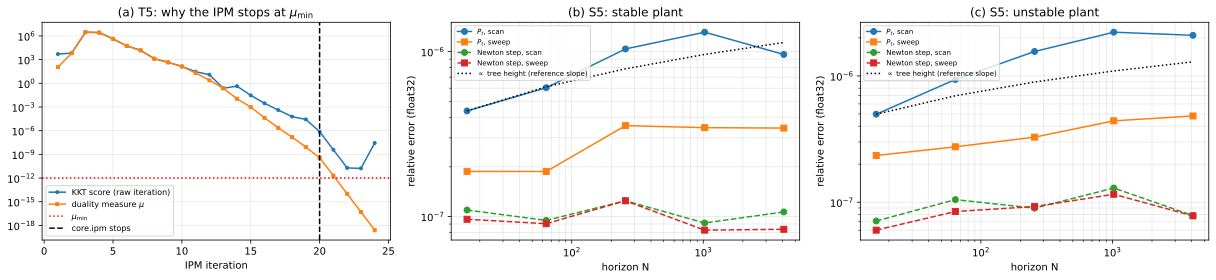

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
its = np.arange(1, len(t5_trace) + 1)
ax[0].semilogy(its, t5_trace[:, 0], 'o-', ms=3, label='KKT score (raw iteration)')
ax[0].semilogy(its, t5_trace[:, 1], 's-', ms=3, label=r'duality measure $\mu$')
ax[0].axhline(1e-12, color='r', ls=':', label=r'$\mu_{\min}$')
ax[0].axvline(int(it_stop), color='k', ls='--', label='core.ipm stops')
ax[0].set(xlabel='IPM iteration', title='(a) T5: why the IPM stops at $\\mu_{\\min}$')
ax[0].legend(fontsize=8)
for a, plant in zip(ax[1:], ('stable', 'unstable')):
    rows = [r for r in s5_rows if r[0] == plant]
    Ns = [r[1] for r in rows]
    a.loglog(Ns, [r[2] for r in rows], 'o-', label='$P_t$, scan')
    a.loglog(Ns, [r[3] for r in rows], 's-', label='$P_t$, sweep')
    a.loglog(Ns, [r[6] for r in rows], 'o--', label='Newton step, scan')
    a.loglog(Ns, [r[7] for r in rows], 's--', label='Newton step, sweep')
    h = lambda N: np.ceil(np.log2(N + 1))
    a.loglog(Ns, [rows[0][2] * h(N) / h(Ns[0]) for N in Ns], 'k:', label=r'$\propto$ tree height (reference slope)')
    a.set(xlabel='horizon N', ylabel='relative error (float32)',
          title=f'({"b" if plant == "stable" else "c"}) S5: {plant} plant')
    a.legend(fontsize=7)
for a in ax:
    a.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

**Summary.**
- *Correctness.* The scan solves every Newton system as accurately as dense LU (T2), is exact in one step on
  equality-constrained problems (T3), and the IPM reaches optima certified by an independent dense QP build,
  identically with scan and sweep (T4). A semidefinite cost breaks the Cholesky combine; the scan then falls back
  to the LU combine and still matches the sweep and the certificate (T6).
- *Stopping rule.* Past the attainable accuracy the raw IPM degrades; `core.ipm` stops and returns its most accurate
  iterate (T5).
- *Stability.* The scan's elements are exactly the Riccati/filter quantities (S1). Rounding errors never amplify in
  relative terms (S2), are damped by the closed loop (S3–S4), and do not grow with $N$ beyond the tree height, for
  stable and unstable plants alike (S5). Large barrier weights do not hurt it on inputs (S6a). On the quadrotor QP,
  where near convergence $\kappa=\bar P/\beta\approx10^{15}$ (S6b), the Cholesky combine and one step of iterative
  refinement keep its attainable accuracy far below the SQP tolerance; the floors themselves are rounding noise
  (reordering the rows moves them by up to two orders of magnitude), and the sweep's are usually lower.
- *Where it breaks.* Without detectability the LQ problem itself is exponentially ill-conditioned; scan and sweep
  both lose accuracy, and $\lambda>0$ repairs both (S7). The quasi variant fails structurally on the quadrotor (S8).
  Shooting is exponentially ill-conditioned for every $\lambda$ (S9).
- *IPM options and the CUDA kernel.* Every IPM option reaches the same certified optimum (T7); `core.cholesky_ok`
  tells when the Cholesky combine is valid (T8). The whole IPM as one CUDA kernel takes the JAX IPM's iterates and
  reaches the same certified optima (T9), and with `precision='float32'` the same certified optima as the JAX IPM
  with that switch. A float32 factorization cannot reach the quadrotor tolerance, however many
  refinement steps; used only while the duality measure exceeds $10^{-5}$ it costs neither accuracy nor iterations
  (S10).